# 4.4 Important Distribution Concepts

**Goal:** connect probability mass, density, accumulation, parameters, moments, empirical distributions, and quantiles to probabilistic ML.

**Prerequisites:** notebooks 4.1–4.3 and Module 2 descriptive statistics.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. If needed, install them in your chosen environment with `python3 -m pip install numpy scipy matplotlib`. Open in JupyterLab, Jupyter Notebook, or VS Code with a Python kernel. Use **Restart Kernel and Run All** to reproduce the saved text and figure outputs. Every notebook is self-contained; random examples use a local fixed seed. All data are synthetic or idealized model calculations, and no downloads are needed.

## Contents
1. Probability mass and probability density
2. Cumulative probability
3. Distribution parameters
4. Skewness
5. Kurtosis
6. Standardization
7. Empirical distribution
8. Quantile functions
9. Generative models, Gaussian Naive Bayes, and variational inference
10. Practice and solutions

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate, special

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
rng = np.random.default_rng(2026)

from scipy import optimize
from scipy.special import logsumexp

## 1. Probability Mass and Probability Density

Probability mass assigns positive weight to individual values in a discrete model: $p(x)=P(X=x)$. A density assigns weight per unit interval: $P(a<X<b)=\int_a^bf(x)\,dx$ in an absolutely continuous model. Summing density heights at arbitrary grid points is not a probability calculation unless the interval widths and approximation rule are included.

A discrete PMF sums to 1 over its full support. A continuous PDF integrates to 1 over its full support. Either can be used in a likelihood for the corresponding observation model, but densities carry inverse measurement units. Raw density values are not unit-free confidence scores and should not be compared casually across different representations.

**Worked example: units change density height.** If time X is in seconds and Y=1000X is in milliseconds, $f_Y(y)=f_X(y/1000)/1000$. The height changes by a factor of 1000 while corresponding interval probabilities stay equal. More generally a monotone differentiable transform requires a Jacobian factor in its density. Ignoring it can make a generative likelihood mathematically incorrect.

A mixed model can assign mass 0.3 at exactly zero and a continuous density for positive values carrying the remaining probability 0.7. A simple ordinary PDF alone cannot encode the point mass; use the full mixture's CDF or event probabilities.

In [2]:
seconds = stats.expon(scale=2)
milliseconds = stats.expon(scale=2000)
print("Density at 1 second:", seconds.pdf(1))
print("Density at 1000 milliseconds:", milliseconds.pdf(1000))
print("Probability below 1 second:", seconds.cdf(1))
print("Probability below 1000 milliseconds:", milliseconds.cdf(1000))
assert np.isclose(milliseconds.pdf(1000), seconds.pdf(1)/1000)
assert np.isclose(milliseconds.cdf(1000), seconds.cdf(1))
print("Mixed model P(X=0)=0.3; P(X <= 1)=", 0.3+0.7*seconds.cdf(1))

Density at 1 second: 0.3032653298563167
Density at 1000 milliseconds: 0.00030326532985631673
Probability below 1 second: 0.3934693402873666
Probability below 1000 milliseconds: 0.3934693402873666
Mixed model P(X=0)=0.3; P(X <= 1)= 0.5754285382011566


## 2. Cumulative Probability

$F(x)=P(X\le x)$ accumulates mass or density up to x. The survival function $S(x)=P(X>x)$ is the remaining upper-tail probability. For a continuous variable, $P(a\le X\le b)=F(b)-F(a)$; for an integer-valued variable use $F(b)-F(a-1)$ for integer a,b.

**Worked example:** for a standard normal variable, $P(Z>9)$ is extremely small. Computing `1-cdf(9)` can round to zero because the CDF is too close to 1 for the floating-point representation. A dedicated `sf` or `logsf` computes small tail probabilities more reliably. Numerical zero can be a rounding result, not mathematical impossibility.

CDFs need not be strictly increasing. Discrete jumps and gaps in support make ordinary algebraic inverses inadequate; a generalized inverse is used for quantiles below.

In [3]:
print("Naive upper tail 1-cdf(9):", 1-stats.norm.cdf(9))
print("Direct upper tail sf(9):", stats.norm.sf(9))
print("Log upper tail:", stats.norm.logsf(9))
assert stats.norm.sf(9) > 0

Naive upper tail 1-cdf(9): 0.0
Direct upper tail sf(9): 1.1285884059538324e-19
Log upper tail: -43.62814911333213


## 3. Distribution Parameters

Parameters index distributions within a family; statistics estimate or summarize from observed samples. Some parameters correspond to familiar moments, but not all.

| Parameter type | Typical role | Example/caution |
|---|---|---|
| Location | Shift on the value axis | Normal $\mu$ is also its mean |
| Scale | Positive rescaling | Normal scale is SD; gamma scale is not generally SD |
| Shape | Change relative geometry | Gamma shape, beta shape pair, Weibull shape |
| Probability | Control event chance | Bernoulli p∈[0,1] |
| Count/size | Constrain repetitions or population | Binomial n, hypergeometric N,K,n |
| Rate | Expected events per unit exposure | Exponential rate is inverse scale |

**Worked example:** Normal(0,1) and Normal(10,4²) differ by location and scale but have the same standardized shape. Gamma(shape=1,scale=2) and Gamma(shape=4,scale=2) differ in shape as well as mean/variance. A parameter called “scale” is not automatically a standard deviation or a rate.

Identifiability and support restrictions matter in modeling. A zero-variance normal is a degenerate point mass, not an ordinary normal density with `scale=0`. Parameters must satisfy the family's domain.

## 4. Skewness

For a finite third absolute moment and positive finite variance,
$$\gamma_1=\mathbb E[(X-\mu)^3]/\sigma^3.$$
It is a dimensionless third-moment measure. Positive values commonly reflect an extended right tail; negative values an extended left tail. Symmetry implies zero skewness when moments exist, but zero skewness does not imply symmetry or normality.

Exponential skewness is 2; Gamma(shape=α) has skewness $2/\sqrt\alpha$. A large gamma shape becomes less skewed, consistent with its sum-of-waiting-times interpretation for integer shapes. Empirical moment estimates and bias-adjusted sample estimates need not coincide.

## 5. Kurtosis

For a finite fourth moment and positive finite variance,
$$\beta_2=\mathbb E[(X-\mu)^4]/\sigma^4,\qquad\gamma_2=\beta_2-3.$$
$\beta_2$ is Pearson kurtosis and $\gamma_2$ is excess kurtosis. Normal excess is 0; exponential excess is 6. Gamma(shape=α) has excess $6/\alpha$. Kurtosis concerns standardized fourth-moment/extreme-value behavior and should not be reduced to “peakedness.” Equal kurtosis to a normal does not establish normality.

The `stats(...,moments="sk")` results used below report skewness and **excess** kurtosis. Some distributions lack the required moments; a finite sample still yields numerical shape summaries but does not establish that theoretical moments exist.

In [4]:
for name, model in [("Normal", stats.norm()), ("Exponential", stats.expon()),
                    ("Gamma shape=4", stats.gamma(a=4)), ("Beta(2,2)", stats.beta(2, 2))]:
    skew, excess = model.stats(moments="sk")
    print(f"{name}: skew={float(skew):.4f}, excess kurtosis={float(excess):.4f}, Pearson={float(excess)+3:.4f}")
assert np.isclose(stats.expon().stats(moments="k"), 6)
assert np.isclose(stats.gamma(a=4).stats(moments="s"), 1)

Normal: skew=0.0000, excess kurtosis=0.0000, Pearson=3.0000
Exponential: skew=2.0000, excess kurtosis=6.0000, Pearson=9.0000
Gamma shape=4: skew=1.0000, excess kurtosis=1.5000, Pearson=4.5000
Beta(2,2): skew=0.0000, excess kurtosis=-0.8571, Pearson=2.1429


## 6. Standardization

For a finite mean $\mu$ and positive finite SD $\sigma$, $Z=(X-\mu)/\sigma$ has mean 0 and variance 1. If X is normal, Z is standard normal; otherwise its standardized shape remains different. Under positive affine transforms, skewness and kurtosis are unchanged. A negative multiplier reverses the sign of skewness but leaves kurtosis unchanged.

**Worked example:** an exponential variable with rate 1 has mean and SD both 1, so Z=X-1 has support [-1,∞), mean 0, variance 1, skewness 2, and excess kurtosis 6. Its mean/variance match the standard normal but its support and tails do not.

For ML preprocessing, training-estimated means and scales should be applied unchanged to held-out data. A held-out dataset need not have mean 0 or SD 1 after that transform. Standardization is a feature transform, not proof of a distributional model or calibrated uncertainty.

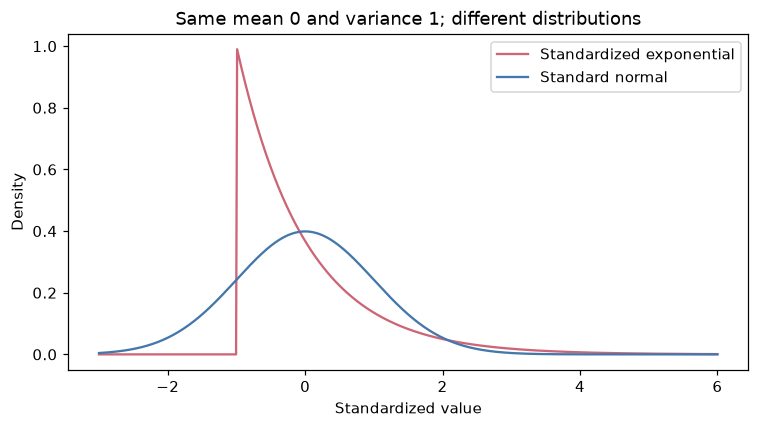

In [5]:
grid = np.linspace(-3, 6, 601)
standardized_exp = stats.expon(loc=-1, scale=1)
fig, ax = plt.subplots()
ax.plot(grid, standardized_exp.pdf(grid), label="Standardized exponential", color="#CC6677")
ax.plot(grid, stats.norm.pdf(grid), label="Standard normal", color="#4477AA")
ax.set(title="Same mean 0 and variance 1; different distributions", xlabel="Standardized value", ylabel="Density")
ax.legend()
fig.tight_layout()
plt.show()
assert np.isclose(standardized_exp.mean(), 0) and np.isclose(standardized_exp.var(), 1)

## 7. Empirical Distribution

For observed $x_1,\ldots,x_n$, the empirical distribution puts mass 1/n at each observation, combining weights when values repeat. Its empirical CDF is
$$F_n(x)=\frac1n\sum_{i=1}^n\mathbf1\{x_i\le x\}.$$
It is a right-continuous step function even when observations were generated from a continuous distribution. It describes the observed sample, not an automatically validated future population distribution.

**Worked example:** observations 1,1,2,4 have masses 1/2 at 1, 1/4 at 2, and 1/4 at 4; $F_n(2)=3/4$. A histogram groups this information, and KDE smooths it under a bandwidth choice. Neither is identical to the raw empirical distribution.

For IID observations, the ECDF consistently estimates the population CDF under standard results. Repeated or selected records can break the intended interpretation: an empirical distribution of sessions weights heavy users more than a distribution with one record per user.

F_n(1): 0.5 F_n(2): 0.75 F_n(3): 0.75


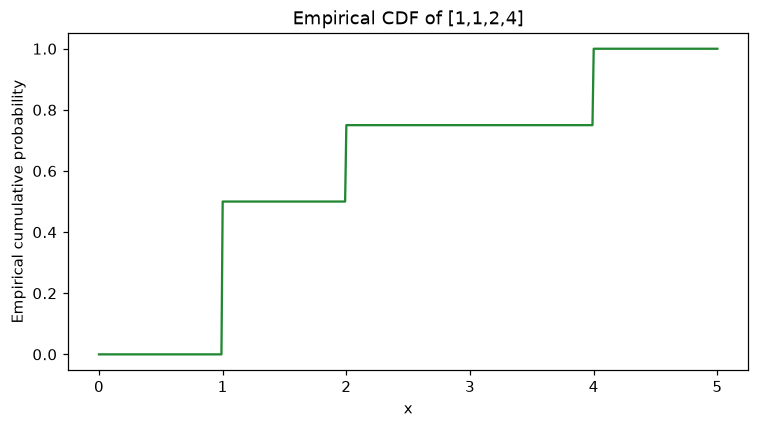

In [6]:
observed = np.array([1.0, 1.0, 2.0, 4.0])
ordered = np.sort(observed)
def ecdf(x):
    return np.searchsorted(ordered, x, side="right")/len(ordered)
print("F_n(1):", ecdf(1), "F_n(2):", ecdf(2), "F_n(3):", ecdf(3))
grid = np.linspace(0, 5, 501)
fig, ax = plt.subplots()
ax.plot(grid, ecdf(grid), color="#228833")
ax.set(title="Empirical CDF of [1,1,2,4]", xlabel="x", ylabel="Empirical cumulative probability", ylim=(-0.05, 1.05))
fig.tight_layout()
plt.show()
assert ecdf(2) == 0.75

## 8. Quantile Functions

For $0<u<1$, a generalized inverse CDF is
$$Q(u)=\inf\{x:F(x)\ge u\}.$$
For continuous strictly increasing CDFs on their support it is the ordinary inverse, but discrete quantiles can stay constant over intervals of u. SciPy calls this the **percent point function**, `ppf`.

**Worked example:** Bernoulli(p=0.3) has mass 0.7 at 0. Thus $Q(0.6)=0$, while $Q(0.8)=1$. In general $F(Q(u))\ge u$, with equality under the continuous strictly increasing conditions. The central 90% normal model interval uses quantiles 0.05 and 0.95; it describes outcomes for known parameters, not a confidence interval for an estimated mean.

An interpolated **sample quantile estimator** is not necessarily the inverse ECDF. For observed [1,1,2,4], at u=0.6 the inverse ECDF is 2 while type-7 linear interpolation gives 1.8. Both conventions can be useful, but must be named. NumPy's `method="inverted_cdf"` follows the empirical generalized-inverse convention for interior probabilities.

### Inverse-transform generation

If U is uniform on (0,1), then $Q(U)$ has CDF F under the generalized-inverse construction. For exponential rate λ, $Q(u)=-\ln(1-u)/\lambda$. `-log1p(-u)` is accurate near zero. A pseudorandom generator approximates this with finite-precision values; the demonstration below avoids u=1, where this unbounded quantile diverges.

In [7]:
print("Bernoulli p=0.3 quantiles:", stats.bernoulli(0.3).ppf([0.6, 0.8]))
print("Inverse ECDF at 0.6:", np.quantile(observed, 0.6, method="inverted_cdf"))
print("Linear sample quantile at 0.6:", np.quantile(observed, 0.6, method="linear"))
uniform_numbers = rng.random(20000)
rate = 2.0
samples = -np.log1p(-uniform_numbers)/rate
print("Inverse-transform exponential sample mean:", samples.mean(), "model mean:", 1/rate)
assert np.isclose(np.quantile(observed, 0.6, method="linear"), 1.8)
# Deterministic check of the inverse identity rather than a random convergence assertion.
probs = np.array([0.1, 0.5, 0.9])
assert np.allclose(stats.expon(scale=0.5).cdf(-np.log1p(-probs)/rate), probs)

Bernoulli p=0.3 quantiles: [0. 1.]
Inverse ECDF at 0.6: 2.0
Linear sample quantile at 0.6: 1.7999999999999998
Inverse-transform exponential sample mean: 0.5018315985583122 model mean: 0.5


## 9. AI/ML applications

### Gaussian Naive Bayes

A Gaussian Naive Bayes class score is $\log P(C=c)+\sum_j\log f_j(x_j\mid c)$ under conditional independence and Gaussian feature-density assumptions. Normalize scores with log-sum-exp. Density terms themselves are not class probabilities; Bayes' normalization creates a posterior under the fitted model. Near-zero fitted variances need a documented regularization policy, and predictive probabilities still need calibration evaluation.

In [8]:
class_priors = np.array([0.6, 0.4])
class_means = np.array([[0.0, 1.0], [2.0, 3.0]])
class_sds = np.array([[1.0, 0.8], [1.2, 1.0]])
x = np.array([1.5, 2.5])
log_scores = np.log(class_priors)+stats.norm.logpdf(x, loc=class_means, scale=class_sds).sum(axis=1)
class_posterior = np.exp(log_scores-logsumexp(log_scores))
print("Gaussian Naive Bayes class probabilities:", class_posterior)
assert np.isclose(class_posterior.sum(), 1)

Gaussian Naive Bayes class probabilities: [0.13469411 0.86530589]


### Variational inference: a small, checkable illustration

Variational inference chooses a tractable q to approximate a posterior $p(\theta\mid D)$, often maximizing an **evidence lower bound** (ELBO):
$$\operatorname{ELBO}(q)=\mathbb E_q[\log p(D,\theta)-\log q(\theta)],$$
$$\log p(D)=\operatorname{ELBO}(q)+\operatorname{KL}(q\Vert p(\theta\mid D)).$$
The KL divergence is nonnegative when well defined. Restricting q to a convenient family can simplify computation but can miss multimodality, dependence, or tail uncertainty. This is an approximation method, not a particular observation distribution.

**Worked example with a known answer:** prior $\theta\sim\mathcal N(0,1)$, observation $y=1.25$ with $y\mid\theta\sim\mathcal N(\theta,0.5^2)$. The exact posterior is $\mathcal N(1,0.2)$. Choose $q=\mathcal N(m,s^2)$ and minimize
$$\operatorname{KL}(q\Vert p)=\tfrac12\left[\frac{s^2+(m-1)^2}{0.2}-1+\ln\frac{0.2}{s^2}\right].$$
The optimum is m=1, $s^2=0.2$ because this approximation family contains the true posterior. We parameterize s as `exp(log_s)` to keep it positive. This example checks the optimization idea; real variational methods generally need expectations of the joint model because the exact posterior is not available in closed form.

Variational mean: 0.9999989319168076 variance: 0.20000020942044502
KL to exact posterior: 3.1261191615584115e-12
Next-observation predictive mean/variance: 1.0 0.45


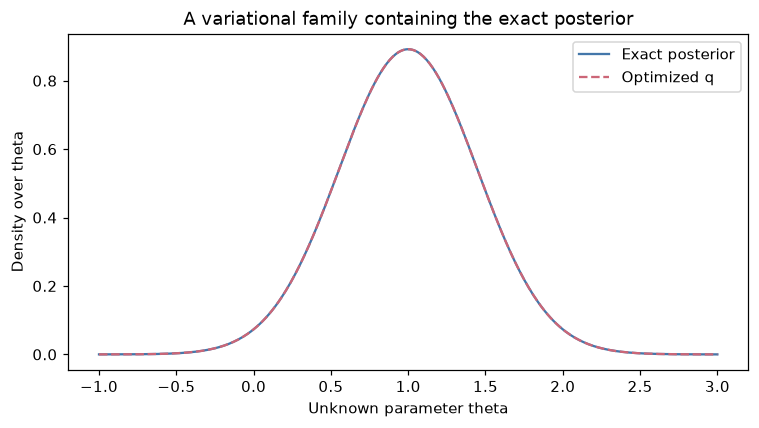

In [9]:
target_mean, target_var = 1.0, 0.2

def normal_kl(parameters):
    mean, log_sd = parameters
    variance = np.exp(2*log_sd)
    return 0.5*((variance+(mean-target_mean)**2)/target_var-1+np.log(target_var/variance))

result = optimize.minimize(normal_kl, x0=np.array([0.0, 0.0]), method="BFGS")
q_mean, q_log_sd = result.x
q_sd = np.exp(q_log_sd)
print("Variational mean:", q_mean, "variance:", q_sd**2)
print("KL to exact posterior:", normal_kl(result.x))
assert np.isclose(q_mean, target_mean, atol=1e-4)
assert np.isclose(q_sd**2, target_var, atol=1e-4)
assert normal_kl(result.x) < 1e-8
# Posterior predictive outcome variance adds new observation noise to parameter uncertainty.
predictive_variance = target_var+0.5**2
print("Next-observation predictive mean/variance:", target_mean, predictive_variance)
grid = np.linspace(-1, 3, 401)
fig, ax = plt.subplots()
ax.plot(grid, stats.norm.pdf(grid, target_mean, np.sqrt(target_var)), label="Exact posterior", color="#4477AA")
ax.plot(grid, stats.norm.pdf(grid, q_mean, q_sd), "--", label="Optimized q", color="#CC6677")
ax.set(title="A variational family containing the exact posterior", xlabel="Unknown parameter theta", ylabel="Density over theta")
ax.legend()
fig.tight_layout()
plt.show()

## Practice

1. Why does a density height change after converting seconds to milliseconds while a matching interval probability does not?
2. Is a numerical `1-cdf(x)` equal to zero sufficient evidence that a tail is mathematically impossible?
3. A distribution has skewness 0 and excess kurtosis 0. Is it necessarily normal?
4. What are the support and skewness of a rate-1 exponential after standardization?
5. For [1,1,2,4], find $F_n(1)$, $F_n(3)$, and the inverse-ECDF quantile at 0.6.
6. For exponential rate 3, write $Q(u)$ and evaluate its median symbolically.
7. Why is the Gaussian Naive Bayes product of feature densities not itself a class probability?
8. When will a normal variational family fail to reproduce a multimodal posterior exactly?
9. Distinguish a predictive interval for an outcome from a credible interval for a parameter.

## Solutions

1. Density has inverse units and transforms with a Jacobian; integration over the corresponding widened millisecond interval cancels that scale change.
2. No. Floating-point cancellation can round a small nonzero tail to zero. Use `sf`/`logsf` for accurate upper-tail calculations.
3. No. A few moments cannot uniquely identify the distribution in general; nonnormal distributions can share those summaries.
4. Support [-1,∞), skewness 2. Mean and variance become 0 and 1 without becoming normal.
5. 1/2, 3/4, and 2. The type-7 interpolated sample quantile instead gives 1.8 at 0.6.
6. $Q(u)=-\ln(1-u)/3$; median $\ln2/3$.
7. It is a likelihood density conditional on class and depends on units. Combine it with priors and normalize across classes using Bayes' rule.
8. An ordinary nondegenerate single normal has one mode and cannot represent separated multiple modes exactly. An optimization result cannot remove that family limitation.
9. The predictive interval concerns an uncertain new observation, including outcome variation; the credible interval concerns uncertainty about a parameter under a posterior model.

**Readiness check:** identify units, moment existence, quantile conventions, and the random quantity represented by a distribution before interpreting model outputs.

**Next:** [4.5 Important Theorems](5_Important-Theorems.ipynb).